# Logistic regression: do its assumptions hold, and if so, how accurate is it?

**Goal:** give every booking a chance (0 to 1) of cancelling, then judge those chances the way the client does (`contract.py`).

Logistic regression gives each clue a weight, adds the weights up, and turns the total into a chance. It is simple and easy to explain, but it is only reliable when its assumptions hold.

**What this notebook does, in order**

1. **Set up** and load the bookings, split by time into *train* (the model learns), *choose* (we pick settings and the buffer) and *proof* (the final exam).
2. **Check the assumptions** of logistic regression on the train period.
3. **Gate.** If every *must-pass* assumption holds, we train. If one fails, the notebook stops and says which.
4. **Train** on train only.
5. **Accuracy**: ordinary classification scores on the choose period.
6. **Accuracy by the contract**: turn the chances into *k* (extra rooms to sell) and score euros, empty rooms, walked guests and walks per 1,000, next to the client's flat rule.
7. **Proof** (the final exam, off by default).

This notebook replaces the logistic regression part of `src/all_models.py`. The *k* step in section 6 is the same rule as in `06_k_calculator.ipynb`.

## 1. Set up

In [108]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 200)

# --- where is everything? (works whether Jupyter starts in notebooks/ or in the project root) ---
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists())
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# --- chart look: one blue line, one orange highlight, quiet grid, dark text ---
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
})

Three switches control the run:

| Switch | Default | Meaning |
|---|---|---|
| `TUNE` | `False` | `True` runs the two-stage search on **train only** (slower), shows every trial, and saves the best setting to `models/hyperparams.json`. `False` shows the results saved by the last run. |
| `RUN_PROOF` | `False` | The proof period is the final exam. Keep it `False` while experimenting. |
| `FORCE_TRAIN` | `False` | `True` trains even if a *must-pass* assumption fails. Not recommended. |

In [109]:
TUNE = False         # True  = run the tuning searches on TRAIN and save the best (slower). False = show the results saved by the last run
RUN_PROOF = True      # the proof period is the FINAL exam: leave this False until everything is decided
FORCE_TRAIN = False   # True  = train even if a MUST-PASS assumption fails (not recommended)

## 2. Load the bookings and split them by time

In [110]:
import data               # the starter's data.py: reads hotels.csv (and downloads it if it is missing)
import features           # src/features.py: our cleaning + the Bin 1 clue columns (known on the day of booking)
import contract           # src/contract.py: the client's scoring file, used exactly as it is and never edited

raw = data.read_raw()                                     # every booking, exactly as exported
bookings = features.clean_bookings(raw)            # the documented cleaning choices
train, choose, proof = contract.split_periods(bookings)   # split by arrival date, as the contract says
train, choose, proof = [features.add_features(part) for part in (train, choose, proof)]

FEATURES = features.bin1_features                  # the clues known on the day of booking
NUMERIC = features.bin1_numeric_cols
CATEGORICAL = features.bin1_categorical_cols

print(f"bookings: train {len(train):,} | choose {len(choose):,} | proof {len(proof):,}")
print("The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.")

bookings: train 49,108 | choose 29,482 | proof 40,619
The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.


## 3. Do the assumptions of logistic regression hold?

We test them on the **train period only**, before any final model is fitted. Each check is either

- **must pass**: if it fails, the model's chances cannot be trusted, so the notebook stops (status **FAIL**), or
- **advisory**: if it fails, the model still works but is weaker. We record it and still train (status **WARN**).

| # | Assumption | Why it matters here | How it is tested | Type |
|---|---|---|---|---|
| A1 | The outcome is yes/no | Logistic regression models the chance of one of two outcomes | `is_canceled` holds only 0 and 1 | must pass |
| A2 | No leakage | A clue only known after the stay (`reservation_status`) gives the answer away: the scores look perfect and are useless | no clue comes from Bin 2 or Bin 3 | must pass |
| L2 | No multicollinearity | Two clues saying the same thing make the weights swing | VIF < 5 for the numeric clues | must pass |
| L3 | Each numeric clue is a straight line in the log-odds | The model can only draw straight lines | let one clue bend; if held-out log loss improves by more than 1%, the line is too stiff | advisory |
| | Independent bookings | The chances of bookings on a night are added as if independent | **cannot be tested before the model exists**: tested after fitting, in section 6 | diagnostic |

L3 is advisory by design: a stiff line costs some accuracy but does not make the chances invalid. To make it blocking, change `must_pass=False` in its `check(...)` call.

In [111]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CHECKS = []    # one row per assumption


def check(name, passed, evidence, must_pass=True):
    """Record one assumption.
       must_pass=True  -> if it fails the status is FAIL and training is stopped.
       must_pass=False -> if it fails the status is WARN: we note it and still train."""
    status = "PASS" if passed else ("FAIL" if must_pass else "WARN")
    CHECKS.append({"assumption": name, "status": status,
                   "type": "must pass" if must_pass else "advisory", "evidence": evidence})

def make_preparer(scale_numbers):
    """Turn the clue columns into numbers. Everything it learns, it learns from the rows it is fitted on."""
    text_step = OneHotEncoder(handle_unknown="ignore", min_frequency=20)   # rare values are grouped together
    number_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("text", text_step, CATEGORICAL),
        ("numbers", number_step, NUMERIC),
    ])

### A. Checks every model needs (data and contract)

In [112]:
y_train = train["is_canceled"]

# A1. the outcome is a yes/no column with both answers present
check("A1  The outcome is yes/no, with no gaps",
      set(y_train.unique()) == {0, 1} and y_train.notna().all(),
      f"values {sorted(int(v) for v in y_train.unique())}; {y_train.mean():.1%} of train bookings cancelled")

# A2. no clue that is only known AFTER the booking (Bin 2 / Bin 3 columns, or the answer itself)
not_known_at_booking = set(features.bin2_features) | set(features.bin3_features) | {"is_canceled"}
leaky = sorted(set(FEATURES) & not_known_at_booking)
check("A2  No clue that is only known after booking (no leakage)", not leaky,
      f"{len(FEATURES)} clues used; leaky ones: {leaky or 'none'}")


### B. Checks specific to logistic regression

In [113]:
import numpy as np

# L2. no multicollinearity: VIF of each numeric clue = the matching diagonal entry of the inverse correlation matrix
correlation = np.corrcoef(train[NUMERIC].astype(float).to_numpy(), rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(correlation)), index=NUMERIC)
check("L2  No multicollinearity among the numeric clues (largest VIF < 5)", vif.max() < 5,
      f"largest VIF {vif.max():.2f} ({vif.idxmax()}); 1 = unrelated to the others")

**L3: is each numeric clue a straight line in the log-odds?**

Instead of a significance test (with tens of thousands of rows, every tiny bend is "significant"), we ask the practical question: *does letting one clue bend actually improve the predictions?* We fit the plain model on the older 80% of train, then again with one clue split into 10 bins (so it may bend), and compare the log loss on the **newest 20% of train**, which neither model saw.

In [114]:
import warnings

from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer

# L3. does letting ONE numeric clue bend improve predictions on data the model did not learn from?
ordered = train.sort_values("arrival_date")
cut = int(len(ordered) * 0.8)
older, newer = ordered.iloc[:cut], ordered.iloc[cut:]


def held_out_log_loss(column_to_bend=None):
    steps = [("text", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
             ("numbers", StandardScaler(), NUMERIC)]
    if column_to_bend:
        steps.append(("bent", KBinsDiscretizer(n_bins=10, encode="onehot", strategy="quantile"), [column_to_bend]))
    pilot = Pipeline([("prepare", ColumnTransformer(steps)), ("model", LogisticRegression(max_iter=2000))])
    pilot.fit(older[FEATURES], older["is_canceled"])
    return log_loss(newer["is_canceled"], pilot.predict_proba(newer[FEATURES])[:, 1])


with warnings.catch_warnings():
    warnings.simplefilter("ignore")       # the binning warns when a clue has only a few distinct values
    straight = held_out_log_loss()
    gain = pd.Series({column: (straight - held_out_log_loss(column)) / straight for column in NUMERIC})

bends = gain[gain > 0.01]
evidence = ("letting these bend helps: " + ", ".join(f"{c} (+{g:.1%})" for c, g in bends.items())
            if len(bends) else "no clue gains more than 1% from bending")
check("L3  Numeric clues are straight lines in the log-odds (bending gains < 1%)", bends.empty, evidence,
      must_pass=False)
display((gain * 100).round(2).rename("log-loss gain from letting this clue bend (%)").to_frame())

,log-loss gain from letting this clue bend (%)
lead_time,3.79
adults,-0.08
children,0.03
babies,0.03
previous_cancellations,-0.67
previous_bookings_not_canceled,0.03
adr,-0.30


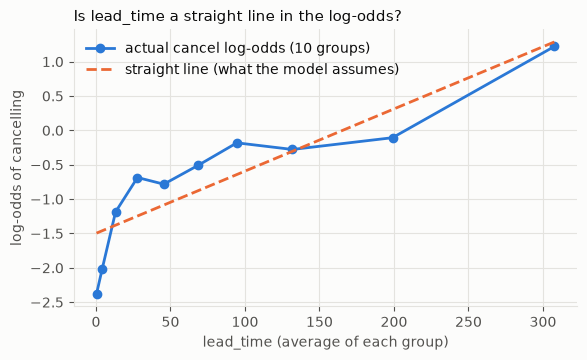

In [115]:
# What does the bend look like for the clue that gains most?
worst = gain.idxmax()
bins = pd.qcut(train[worst], q=10, duplicates="drop")
per_bin = train.groupby(bins, observed=True).agg(x=(worst, "mean"), rate=("is_canceled", "mean"))
rate = per_bin["rate"].clip(0.001, 0.999)
per_bin["log_odds"] = np.log(rate / (1 - rate))
slope, intercept = np.polyfit(per_bin["x"], per_bin["log_odds"], 1)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(per_bin["x"], per_bin["log_odds"], "o-", color=BLUE, markersize=6, label="actual cancel log-odds (10 groups)")
ax.plot(per_bin["x"], intercept + slope * per_bin["x"], "--", color=ORANGE, label="straight line (what the model assumes)")
ax.set_xlabel(f"{worst} (average of each group)")
ax.set_ylabel("log-odds of cancelling")
ax.set_title(f"Is {worst} a straight line in the log-odds?")
ax.legend(frameon=False)
plt.show()

### Verdict

All checks are collected into one table. **FAIL** = a must-pass assumption is broken. **WARN** = an advisory one is, and we carry on.

In [116]:
report = pd.DataFrame(CHECKS).set_index("assumption")
display(report)

failed = report.index[report["status"] == "FAIL"].tolist()
warned = report.index[report["status"] == "WARN"].tolist()
ASSUMPTIONS_OK = not failed
TRAIN_MODEL = ASSUMPTIONS_OK or FORCE_TRAIN

print(f"{(report['status'] == 'PASS').sum()} passed | {len(warned)} warning(s) | {len(failed)} failed")
for name in warned:
    print("   WARN:", name.strip())

if not ASSUMPTIONS_OK:
    verdict = "FAILED (trained anyway: FORCE_TRAIN)"
elif warned:
    verdict = f"PASS with {len(warned)} warning(s)"
else:
    verdict = "PASS"

if not TRAIN_MODEL:
    raise RuntimeError("Must-pass assumption(s) failed, so logistic regression is NOT trained: "
                       + "; ".join(n.strip() for n in failed)
                       + ". Fix the cause, or set FORCE_TRAIN = True to train anyway.")
print("\nVerdict:", "the must-pass assumptions hold -> we train the logistic regression." if ASSUMPTIONS_OK
      else "FORCE_TRAIN is on -> training even though a must-pass assumption failed.")

,status,type,evidence
assumption,,,
"A1 The outcome is yes/no, with no gaps",PASS,must pass,"values [0, 1]; 35.8% of train bookings cancelled"
A2 No clue that is only known after booking (no leakage),PASS,must pass,16 clues used; leaky ones: none
L2 No multicollinearity among the numeric clues (largest VIF < 5),PASS,must pass,largest VIF 1.09 (adr); 1 = unrelated to the others
L3 Numeric clues are straight lines in the log-odds (bending gains < 1%),WARN,advisory,letting these bend helps: lead_time (+3.8%)


3 passed | 1 warning(s) | 0 failed
   WARN: L3  Numeric clues are straight lines in the log-odds (bending gains < 1%)

Verdict: the must-pass assumptions hold -> we train the logistic regression.


## 4. Tune and train the logistic regression

Only reached if the gate above passed. This section shows **how the settings were chosen**: what we tune and why, a wide search, a finer search, a plot, the best setting, and a check that tuning really helps. Every search uses **train only**, in folds that go forward in time, so nothing from the choose or proof periods can influence the choice.

`TUNE = True` runs the searches (slower) and saves the result. `TUNE = False` shows the results saved by the last run.

In [117]:
import datetime
import json

from sklearn.model_selection import TimeSeriesSplit
import all_models                                   # src/all_models.py: the same trainers backtest.py uses
from sklearn.model_selection import GridSearchCV, cross_validate

# ---- how every search in this section is run ----
SEED = 0                                  # fixed seed (the grid search below has none; kept so the tree and forest notebooks match)
N_SPLITS = 3
CV = TimeSeriesSplit(n_splits=N_SPLITS)   # each fold is tested on bookings that come AFTER the ones it learned from
SCORING = {"log_loss": "neg_log_loss", "auc": "roc_auc"}   # log loss decides; AUC is shown for reference
PREFER_SIMPLER = False    # True = among candidates tied with the best, take the simplest (step 5). False = take the lowest log loss

ordered = train.sort_values("arrival_date")               # time order, as TimeSeriesSplit needs
X_tune, y_tune = ordered[FEATURES], ordered["is_canceled"]

EVIDENCE = ROOT / "evidence"
TRIALS_FILE = EVIDENCE / "tuning_logistic_regression_trials.csv"   # every candidate that was tried
SUMMARY_FILE = EVIDENCE / "tuning_logistic_regression.json"        # how the search was run + the choice

trials = summary = None
if not TUNE:
    if TRIALS_FILE.exists() and SUMMARY_FILE.exists():
        trials = pd.read_csv(TRIALS_FILE)
        summary = json.loads(SUMMARY_FILE.read_text())
        print("TUNE = False: showing the results saved by the last tuning run.")
    else:
        print("TUNE = False and nothing is saved yet. Set TUNE = True at the top and run the notebook once.")

TUNE = False: showing the results saved by the last tuning run.


### Step 1. What are we tuning, and why these values?

A *hyper-parameter* is a setting we choose before training. The model cannot learn it from the data, so we try values and keep the one that predicts best on bookings it has not seen. The logistic regression has one that matters here, `C`.

In [118]:
TUNED = pd.DataFrame([{
    "setting": "C",
    "what it controls": "how strongly the model is held back from fitting noise. Small C = strong regularisation (a simpler model); large C = weak (follows the training bookings closely)",
    "range tried": "0.0001 to 100, 13 values on a log scale (step 2), then 9 values zoomed in around the best (step 3)",
    "why this range": "it reaches from a model that is far too simple to one that is barely held back, so the best value cannot be hiding outside it. Log scale because C works in multiples, not in equal steps",
}]).set_index("setting")
with pd.option_context("display.max_colwidth", None):
    display(TUNED)
print("Not tuned: max_iter = 1000 (it only lets the solver finish), the encoding and the scaling (fixed in features.py).")

,what it controls,range tried,why this range
setting,,,
C,how strongly the model is held back from fitting noise. Small C = strong regularisation (a simpler model); large C = weak (follows the training bookings closely),"0.0001 to 100, 13 values on a log scale (step 2), then 9 values zoomed in around the best (step 3)","it reaches from a model that is far too simple to one that is barely held back, so the best value cannot be hiding outside it. Log scale because C works in multiples, not in equal steps"


Not tuned: max_iter = 1000 (it only lets the solver finish), the encoding and the scaling (fixed in features.py).


### Step 2. Wide search: try many values of `C`

Every value in the list is trained and scored on the same three forward-in-time folds. The table lists every candidate, best first. **`log loss`** decides (lower is better), because the safety buffer is built from the *sum* of the chances, so the chances must be honest. `log loss std` is how much the score moved between folds, and `AUC` is shown for reference.

In [119]:
def run_search(c_values):
    """Train and score every C on the same time-ordered folds. Returns one row per candidate."""
    model = Pipeline([
        ("prepare", make_preparer(scale_numbers=True)),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    c_values = [float(f"{c:.6g}") for c in c_values]       # tidy numbers, so the same C is never listed twice
    search = GridSearchCV(model, {"model__C": c_values}, scoring=SCORING, cv=CV, refit=False, n_jobs=-1)
    search.fit(X_tune, y_tune)
    r = pd.DataFrame(search.cv_results_)
    out = pd.DataFrame({
        "C": r["param_model__C"].astype(float),
        "log loss": -r["mean_test_log_loss"],
        "log loss std": r["std_test_log_loss"],
        "AUC": r["mean_test_auc"],
        "fit seconds": r["mean_fit_time"],
    })
    for k in range(N_SPLITS):                               # the score of every single fold, kept as evidence
        out[f"fold {k + 1}"] = -r[f"split{k}_test_log_loss"]
    return out


STAGE1_C = np.logspace(-4, 2, 13)          # 0.0001 ... 100

if TUNE:
    stage1 = run_search(STAGE1_C)
    stage1.insert(0, "stage", 1)
    trials = stage1

if trials is not None:
    shown = trials[trials["stage"] == 1].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    best1 = shown.loc[0, "C"]
    print(f"Best of the wide search: C = {best1:.4g}")
    if best1 in (shown["C"].min(), shown["C"].max()):
        print("-> the best value is at the edge of the range: widen the range and run again.")
    else:
        print("-> the best value is inside the range, so the wide search was wide enough.")

,stage,C,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,1,0.0100,0.4073,0.0605,0.8720,0.4527,0.3272,0.4735,0.4211
1,1,0.0316,0.4085,0.0735,0.8777,0.4379,0.3147,0.4942,0.4166
2,1,0.1000,0.4181,0.0782,0.8798,0.4443,0.3228,0.5142,0.4173
3,1,0.0032,0.4196,0.0429,0.8639,0.5087,0.3613,0.4633,0.4343
4,1,0.3162,0.4319,0.0754,0.8787,0.5741,0.3454,0.5292,0.4212
5,1,1.0000,0.4419,0.0753,0.8770,0.6268,0.3591,0.5412,0.4253
6,1,0.0010,0.4512,0.0238,0.8504,0.5962,0.4183,0.4743,0.4608
7,1,3.1623,0.4513,0.0750,0.8749,0.6563,0.3733,0.5525,0.4280
8,1,10.0000,0.4588,0.0741,0.8736,0.8835,0.3860,0.5606,0.4299
9,1,31.6228,0.4654,0.0737,0.8722,1.0106,0.3963,0.5675,0.4323


Best of the wide search: C = 0.01
-> the best value is inside the range, so the wide search was wide enough.


### Step 3. Finer search around the best region

Now zoom in: nine values within about a factor of three either side of the best value from step 2 (half a power of ten each way).

In [120]:
if TUNE:
    centre = np.log10(trials[trials["stage"] == 1].sort_values("log loss").iloc[0]["C"])
    stage2 = run_search(np.logspace(centre - 0.5, centre + 0.5, 9))
    stage2.insert(0, "stage", 2)
    trials = pd.concat([trials, stage2], ignore_index=True)

if trials is not None:
    shown = trials[trials["stage"] == 2].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    best2 = shown.loc[0, "C"]
    print(f"Best of the fine search: C = {best2:.4g}")
    if best2 in (shown["C"].min(), shown["C"].max()):
        print("-> the best value is at the edge of the zoomed range: the score is still moving, so widen it and run again.")
    else:
        print("-> the best value is inside the zoomed range.")

,stage,C,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,2,0.0133,0.4065,0.0643,0.8738,0.4903,0.3222,0.4780,0.4194
1,2,0.0178,0.4065,0.0679,0.8754,0.4895,0.3183,0.4833,0.4180
2,2,0.0237,0.4071,0.0710,0.8767,0.3788,0.3157,0.4886,0.4171
3,2,0.0100,0.4073,0.0605,0.8720,0.4467,0.3272,0.4735,0.4211
4,2,0.0316,0.4085,0.0735,0.8777,0.3361,0.3147,0.4942,0.4166
5,2,0.0075,0.4088,0.0564,0.8702,0.4781,0.3337,0.4694,0.4234
6,2,0.0056,0.4114,0.0521,0.8682,0.6075,0.3415,0.4664,0.4264
7,2,0.0042,0.4149,0.0475,0.8663,0.5596,0.3507,0.4641,0.4300
8,2,0.0032,0.4196,0.0429,0.8639,0.4468,0.3613,0.4633,0.4343


Best of the fine search: C = 0.01334
-> the best value is inside the zoomed range.


### Step 4. Where does the model underfit and overfit?

Left side of the curve: `C` is so small that the model is held back too much (underfits). Right side: `C` is so large that the model chases noise (overfits). The best `C` sits where the curve is lowest. The bars show how much the score moved between the three folds, so two values whose bars overlap are not really different.

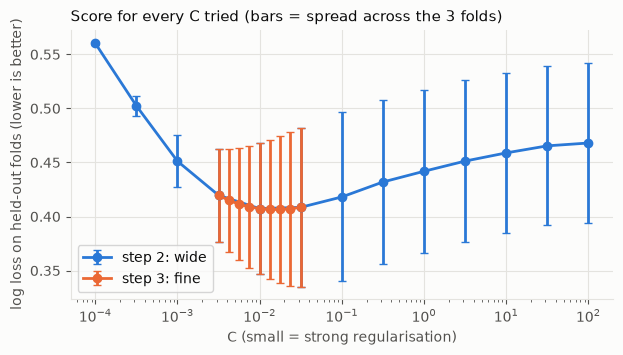

In [121]:
if trials is not None:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for stage, colour, label in ((1, BLUE, "step 2: wide"), (2, ORANGE, "step 3: fine")):
        part = trials[trials["stage"] == stage].sort_values("C")
        ax.errorbar(part["C"], part["log loss"], yerr=part["log loss std"], marker="o", color=colour,
                    label=label, capsize=3)
    ax.set_xscale("log")
    ax.set_xlabel("C (small = strong regularisation)")
    ax.set_ylabel("log loss on held-out folds (lower is better)")
    ax.set_title("Score for every C tried (bars = spread across the 3 folds)")
    ax.legend()
    plt.show()

### Step 5. The best setting

**Rule:** take the lowest log loss. Another candidate counts as *tied* with it if its average gap to the best, measured **fold by fold**, is smaller than one standard error of that gap. (Comparing fold by fold removes the noise all candidates share, such as one fold simply being a harder period.) Among the tied candidates we choose the simplest model, which here means the strongest regularisation (the smallest `C`). A simpler model generalises better and its chances tend to be better calibrated. Set `PREFER_SIMPLER = False` at the top of this section to take the lowest log loss instead. With only 3 folds the standard error is large, so many candidates count as tied: check the chosen row against the plot in step 4.

In [122]:
if trials is not None:
    fold_cols = [f"fold {k + 1}" for k in range(N_SPLITS)]
    pool = trials.drop_duplicates("C").copy()              # a C tried in both searches counts once
    best = pool.sort_values("log loss").iloc[0]
    gap = pool[fold_cols].sub(best[fold_cols], axis=1)     # this candidate minus the best, fold by fold
    pool["gap to best"] = gap.mean(axis=1)
    pool["one std error"] = gap.std(axis=1, ddof=1) / np.sqrt(N_SPLITS)
    tied = pool[pool["gap to best"] <= pool["one std error"]].sort_values("C").reset_index(drop=True)
    chosen = tied.iloc[0] if PREFER_SIMPLER else best      # tied.iloc[0] = smallest C = strongest regularisation = simplest
    chosen_C = float(chosen["C"])

    print(f"BEST SETTING:  C = {chosen_C:.4g}")
    print(f"  lowest log loss overall: C = {best['C']:.4g} (log loss {best['log loss']:.4f})")
    if PREFER_SIMPLER:
        print(f"  {len(tied)} candidate(s) are tied with it (gap within one standard error); the simplest of them is chosen")
    else:
        print("  PREFER_SIMPLER = False: the lowest log loss is taken as it is")
    print(f"  chosen: log loss {chosen['log loss']:.4f}, AUC {chosen['AUC']:.4f}")
    display(tied[["C", "log loss", "AUC", "gap to best", "one std error"]].round(4))

    if TUNE:
        summary = {
            "model": "logistic regression",
            "tuned_on": (f"train period only ({train['arrival_date'].min().date()} to {train['arrival_date'].max().date()}), "
                         f"{N_SPLITS} forward-in-time folds (TimeSeriesSplit)"),
            "scoring": "mean log loss over the folds (lower is better); AUC recorded for reference",
            "seed": SEED,
            "setting_searched": "model__C",
            "stage 1 (wide) values": [float(c) for c in STAGE1_C],
            "stage 2 (fine) values": [float(c) for c in sorted(trials[trials["stage"] == 2]["C"])],
            "n_trials": int(len(pool)),
            "prefer_simpler": PREFER_SIMPLER,
            "rule": ("lowest log loss; candidates whose fold-by-fold gap to it is within one standard error count as tied, "
                     "and the simplest of them (smallest C) is chosen" if PREFER_SIMPLER else "lowest log loss"),
            "lowest_log_loss_C": float(best["C"]),
            "chosen": {"model__C": chosen_C},
            "chosen_log_loss": float(chosen["log loss"]),
        }

BEST SETTING:  C = 0.01334
  lowest log loss overall: C = 0.01334 (log loss 0.4065)
  PREFER_SIMPLER = False: the lowest log loss is taken as it is
  chosen: log loss 0.4065, AUC 0.8738


,C,log loss,AUC,gap to best,one std error
0,0.0032,0.4196,0.8639,0.0131,0.0156
1,0.0042,0.4149,0.8663,0.0084,0.0123
2,0.0056,0.4114,0.8682,0.0049,0.0090
3,0.0075,0.4088,0.8702,0.0023,0.0059
4,0.0100,0.4073,0.8720,0.0008,0.0028
5,0.0133,0.4065,0.8738,0.0000,0.0000
6,0.0178,0.4065,0.8754,0.0000,0.0028
7,0.0237,0.4071,0.8767,0.0006,0.0052
8,0.0316,0.4085,0.8777,0.0020,0.0072
9,0.1000,0.4181,0.8798,0.0116,0.0123


### Step 6. Does tuning help? Tuned vs default

The default setting (`C = 1`) and the chosen setting, scored on the same three folds. If the gain is tiny, tuning did not matter much, and that is also a result worth reporting.

In [123]:
def fold_scores(c_value):
    model = Pipeline([
        ("prepare", make_preparer(scale_numbers=True)),
        ("model", LogisticRegression(C=c_value, max_iter=1000)),
    ])
    r = cross_validate(model, X_tune, y_tune, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.DataFrame({"log loss": -r["test_log_loss"], "AUC": r["test_auc"]}, index=range(1, N_SPLITS + 1))


if trials is not None:
    if TUNE:
        default, tuned = fold_scores(1.0), fold_scores(chosen_C)
        summary["vs_default"] = {
            "default C": 1.0, "chosen C": chosen_C,
            "default log loss": float(default["log loss"].mean()), "tuned log loss": float(tuned["log loss"].mean()),
            "default AUC": float(default["AUC"].mean()), "tuned AUC": float(tuned["AUC"].mean()),
            "default log loss by fold": [float(x) for x in default["log loss"]],
            "tuned log loss by fold": [float(x) for x in tuned["log loss"]],
        }
    v = summary["vs_default"]
    compare = pd.DataFrame({
        "default (C = 1)": [v["default log loss"], v["default AUC"]],
        f"tuned (C = {v['chosen C']:.4g})": [v["tuned log loss"], v["tuned AUC"]],
    }, index=["mean log loss (lower is better)", "mean AUC (higher is better)"])
    compare["difference"] = compare.iloc[:, 1] - compare.iloc[:, 0]
    display(compare.round(4))

    gain = v["default log loss"] - v["tuned log loss"]
    if gain > 0.002:
        print(f"-> tuning helped: the log loss fell by {gain:.4f}.")
    elif gain >= -0.002:
        print(f"-> the difference is tiny ({gain:+.4f} log loss): the default was already close. Report that tuning changed little.")
    else:
        print(f"-> the chosen setting is worse than the default by {-gain:.4f} log loss on these folds. Look at the plot in step 4 before using it.")

,default (C = 1),tuned (C = 0.01334),difference
mean log loss (lower is better),0.4419,0.4065,-0.0353
mean AUC (higher is better),0.8770,0.8738,-0.0032


-> tuning helped: the log loss fell by 0.0353.


### Step 7. Save the choice

With `TUNE = True` this saves three things: the chosen settings in `models/hyperparams.json` (what `backtest.py` trains with), and the full table of trials plus the search summary in `evidence/` (the proof of how the setting was chosen). It also prints a row for `docs/DECISIONS.md`: check the wording, then paste it into the team decisions table.

In [124]:
if TUNE and summary is not None:
    EVIDENCE.mkdir(exist_ok=True)
    trials.to_csv(TRIALS_FILE, index=False)
    SUMMARY_FILE.write_text(json.dumps(summary, indent=2))
    all_models.save_hyperparams("logistic regression", summary["chosen"])
    print("saved: models/hyperparams.json  (the settings backtest.py trains with)")
    print("saved:", TRIALS_FILE.relative_to(ROOT), "and", SUMMARY_FILE.relative_to(ROOT))

if summary is not None:
    v = summary["vs_default"]
    print("\nRow for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:\n")
    print(f"| {datetime.date.today()} | notebooks/03_model_logistic_regression.ipynb | Logistic regression: C = {chosen_C:.4g}. "
          f"Chosen from {summary['n_trials']} trials of C (0.0001 to 100) on train only, {N_SPLITS} forward-in-time folds, scored by log loss. "
          f"Rule: {summary['rule']}. "
          f"Cross-validated log loss {v['tuned log loss']:.4f} against {v['default log loss']:.4f} for the default C = 1. | | | |")


Row for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:

| 2026-11-17 | notebooks/03_model_logistic_regression.ipynb | Logistic regression: C = 0.01334. Chosen from 19 trials of C (0.0001 to 100) on train only, 3 forward-in-time folds, scored by log loss. Rule: lowest log loss. Cross-validated log loss 0.4065 against 0.4419 for the default C = 1. | | | |


### Train the final model

The model used in the rest of this notebook is trained by `all_models.train_logistic`, the same function `backtest.py` calls, with the saved settings. So the notebook and `backtest.py` always train the same model.

In [125]:
model = all_models.train_logistic(train)                  # learn from train only, with the saved settings
print("settings used:", all_models.load_hyperparams("logistic regression") or "none saved yet, so the defaults")
print("trained on", f"{len(train):,}", "train bookings")

settings used: {'model__C': 0.0133352}
trained on 49,108 train bookings


In [126]:
# What drives cancellations? One weight per encoded clue: positive = more likely to cancel.
names = model.named_steps["prepare"].get_feature_names_out()
weights = pd.Series(model.named_steps["model"].coef_[0], index=names).sort_values()
display(pd.DataFrame({"most protective (lower cancel odds)": weights.head(8).index,
                      "weight": weights.head(8).round(2).values,
                      "most risky (higher cancel odds)": weights.tail(8)[::-1].index,
                      "weight ": weights.tail(8)[::-1].round(2).values}))

,most protective (lower cancel odds),weight,most risky (higher cancel odds),weight
0,text__deposit_type_No Deposit,-1.58,numbers__previous_cancellations,1.99
1,numbers__previous_bookings_not_canceled,-0.70,text__deposit_type_Non Refund,1.75
2,text__country_DEU,-0.62,text__country_PRT,1.64
3,text__country_FRA,-0.54,text__agent_9,0.93
4,text__agent_30,-0.47,text__agent_134,0.85
5,text__agent_28,-0.44,text__agent_17,0.71
6,text__country_AUT,-0.43,text__country_AGO,0.59
7,text__customer_type_Contract,-0.43,text__customer_type_Transient,0.55


## 5. Accuracy on the choose period

The model learned from train only, so the choose period is data it has never seen. First the ordinary scores, then (section 6) the scores that matter to the client.

In [127]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)

def predict_chances(model, df):
    """A chance of cancelling (0 to 1) for every booking."""
    return model.predict_proba(df[FEATURES])[:, 1]     # column 0 = chance of staying, column 1 = chance of cancelling


def get_scores(df, chances):
    """Ordinary classification scores, using 0.5 as the cut-off."""
    answers = df["is_canceled"]
    guesses = (chances >= 0.5).astype(int)
    true_stays, false_cancels, missed_cancels, true_cancels = confusion_matrix(answers, guesses).ravel()
    return {
        "accuracy": accuracy_score(answers, guesses),             # share of bookings guessed right
        "always_stays": 1 - answers.mean(),                       # accuracy if we just said "nobody cancels"
        "auc": roc_auc_score(answers, chances),                   # 0.5 = guessing, 1.0 = perfect
        "log_loss": log_loss(answers, chances),                   # punishes confident wrong chances
        "precision": precision_score(answers, guesses, zero_division=0),   # of "will cancel" guesses, how many did
        "recall": recall_score(answers, guesses),                 # of the real cancels, how many we caught
        "f1": f1_score(answers, guesses),                         # one number mixing precision and recall
        "true_stays": true_stays, "false_cancels": false_cancels,
        "missed_cancels": missed_cancels, "true_cancels": true_cancels,
    }


def show_scores(scores, chances, df):
    table = pd.Series({
        "accuracy": scores["accuracy"],
        "accuracy of always guessing 'stays' (the bar to beat)": scores["always_stays"],
        "AUC": scores["auc"], "log loss": scores["log_loss"],
        "precision": scores["precision"], "recall": scores["recall"], "f1": scores["f1"],
    }, name="choose period")
    display(table.round(3).to_frame())
    display(pd.DataFrame([[scores["true_stays"], scores["false_cancels"]],
                          [scores["missed_cancels"], scores["true_cancels"]]],
                         index=["really stayed", "really cancelled"],
                         columns=["guessed: stays", "guessed: cancels"]))
    beat = "BEATS" if scores["accuracy"] > scores["always_stays"] else "does NOT beat"
    print(f"Accuracy {scores['accuracy']:.3f} {beat} the always-'stays' guess ({scores['always_stays']:.3f}).")
    expected, actual = chances.sum(), int(df["is_canceled"].sum())
    print(f"Chances add up to {expected:,.0f} cancellations; {actual:,} really happened "
          f"({expected / actual:.0%}). The buffer is built from this sum, so this matters.")


chances_choose = predict_chances(model, choose)
scores = get_scores(choose, chances_choose)
show_scores(scores, chances_choose, choose)

,choose period
accuracy,0.742
accuracy of always guessing 'stays' (the bar to beat),0.631
AUC,0.818
log loss,0.489
precision,0.786
recall,0.413
f1,0.541


,guessed: stays,guessed: cancels
really stayed,17371,1227
really cancelled,6389,4495


Accuracy 0.742 BEATS the always-'stays' guess (0.631).
Chances add up to 9,629 cancellations; 10,884 really happened (88%). The buffer is built from this sum, so this matters.


## 6. Accuracy by the contract

The client does not score "was the guess right?". It scores **what the rule costs**, night by night (`docs/EVALUATION_CONTRACT.md`):

1. `contract.nightly_table` adds up the chances of one hotel's bookings on one night: `expected` cancellations and their `spread` (standard deviation).
2. We hold back a safety buffer: **k = floor(expected − z × spread)** extra rooms to sell. `z` is how many standard deviations we hold back (bigger `z` = more careful).
3. `contract.night_cost` compares *k* with what really happened: an empty room costs that night's average stay value, a walked guest costs EUR 300.
4. A rule is acceptable only if it walks **10 or fewer guests per 1,000 arrivals**. We pick the **cheapest `z` that stays inside that limit, on the choose period**.

In [128]:
Z_GRID = [round(i * 0.1, 1) for i in range(0, 41)]   # 0.0 ... 4.0 (a buffer only holds rooms back)
MARGIN_GRID = list(range(0, 61))                       # 0 ... 60 rooms


def calculate_k(nights, buffer, kind="z"):
    """k = how many EXTRA rooms to sell on each night.
       kind="z"      -> k = floor(expected - z x spread). Used for the models.
       kind="margin" -> k = floor(expected) - margin.     Used for the client's flat rule."""
    if kind == "margin":
        k = np.floor(nights["expected"]) - buffer
    else:
        k = np.floor(nights["expected"] - buffer * nights["spread"])
    k = np.clip(k, 0, None)        # k is never below 0
    return k.astype(int)           # whole rooms only


def avg_rooms_held_back(nights, buffer, kind="z"):
    """The buffer expressed in rooms per night, so z and margin can be compared."""
    if kind == "margin":
        return float(buffer)
    return float(buffer * nights["spread"].mean())


def find_best_buffer(nights, kind="z"):
    """Try many buffers and keep the CHEAPEST one that stays inside the walk limit.
       Run this on the CHOOSE period only. Returns the buffer and its score."""
    buffers_to_try = MARGIN_GRID if kind == "margin" else Z_GRID
    best_buffer, best_result = None, None
    for buffer in buffers_to_try:
        result = contract.night_cost(nights, calculate_k(nights, buffer, kind))   # the starter scores it for us
        if result["ceiling_met"]:                                                 # only buffers inside the walk limit count
            if best_result is None or result["cost_eur"] < best_result["cost_eur"]:
                best_buffer, best_result = buffer, result
    if best_result is None:
        raise ValueError("No buffer stayed inside the walk limit. Try a bigger range of buffers.")
    if best_buffer in (buffers_to_try[0], buffers_to_try[-1]):
        print(f"   WARNING: best buffer {best_buffer} is at the edge of the grid; widen the grid.")
    return best_buffer, best_result


def sweep_buffers(nights, kind="z"):
    """The score of EVERY buffer in the grid (for the chart)."""
    grid = MARGIN_GRID if kind == "margin" else Z_GRID
    rows = [{"buffer": b, **contract.night_cost(nights, calculate_k(nights, b, kind))} for b in grid]
    return pd.DataFrame(rows)


def plot_buffer_sweep(sweep, best_buffer, xlabel, title):
    """Left: what each buffer costs. Right: how many guests it walks (the client allows at most 10 per 1,000).
       The grey zone is every buffer that breaks that limit; the orange dot is the cheapest buffer outside it."""
    fig, (ax_cost, ax_walk) = plt.subplots(1, 2, figsize=(11, 3.6))
    within = sweep[sweep["walks_per_1000"] <= contract.WALK_CEILING]
    edge = within["buffer"].min() if len(within) else sweep["buffer"].max()
    best = sweep.loc[sweep["buffer"] == best_buffer].iloc[0]

    ax_cost.plot(sweep["buffer"], sweep["cost_eur"] / 1e6, color=BLUE)
    ax_cost.plot(best_buffer, best["cost_eur"] / 1e6, "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_cost.annotate(f"cheapest safe buffer: {best_buffer}", (best_buffer, best["cost_eur"] / 1e6),
                     xytext=(10, -18), textcoords="offset points", color=MUTED)
    ax_cost.set_ylabel("cost on the choose period (EUR millions)")

    ax_walk.plot(sweep["buffer"], sweep["walks_per_1000"], color=BLUE)
    ax_walk.axhline(contract.WALK_CEILING, color=MUTED, linestyle="--", linewidth=1)
    ax_walk.annotate(f"client limit: {contract.WALK_CEILING:g} per 1,000", (sweep["buffer"].max(), contract.WALK_CEILING),
                     xytext=(0, 4), textcoords="offset points", ha="right", color=MUTED)
    ax_walk.plot(best_buffer, best["walks_per_1000"], "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_walk.set_ylabel("walked guests per 1,000 arrivals")

    for ax in (ax_cost, ax_walk):
        ax.axvspan(sweep["buffer"].min(), edge, color=GRID, alpha=0.6, zorder=0)
        ax.set_xlabel(xlabel)
    ax_cost.set_title(title + ": cost")
    ax_walk.set_title(title + ": walks")
    ax_cost.text(0.02, 0.96, "grey = breaks the walk limit", transform=ax_cost.transAxes, va="top", color=MUTED)
    fig.tight_layout()
    plt.show()

Best buffer on the choose period: z = 0.8 std devs = 2.6 rooms held back per night on average


,logistic regression on the choose period
cost (EUR),1062216.0
empty rooms,2558
walked guests,179
"walks per 1,000 arrivals",9.62
walk limit met (<= 10),True
nights scored,368
nightly error (rooms),5.89


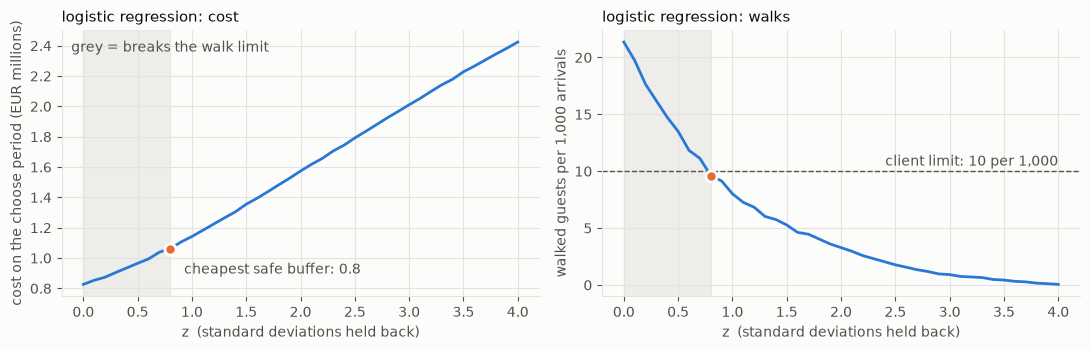

In [129]:
def nightly_error(nights):
    """Average gap, in rooms, between expected and real cancellations per night."""
    return (nights["expected"] - nights["cancelled"]).abs().mean()


nights_choose = contract.nightly_table(choose, chances_choose)      # one row per hotel and night
best_z, best = find_best_buffer(nights_choose)                       # the cheapest z inside the walk limit
rooms_held_back = avg_rooms_held_back(nights_choose, best_z)

print(f"Best buffer on the choose period: z = {best_z} std devs "
      f"= {rooms_held_back:.1f} rooms held back per night on average")
display(pd.Series({
    "cost (EUR)": best["cost_eur"],
    "empty rooms": best["empty_rooms"],
    "walked guests": best["walked_guests"],
    "walks per 1,000 arrivals": best["walks_per_1000"],
    "walk limit met (<= 10)": best["ceiling_met"],
    "nights scored": best["nights"],
    "nightly error (rooms)": round(nightly_error(nights_choose), 2),
}, name="logistic regression on the choose period").to_frame())

sweep = sweep_buffers(nights_choose)
plot_buffer_sweep(sweep, best_z, "z  (standard deviations held back)", "logistic regression")

**Reading the chart.** Cost rises with `z` (more empty rooms) while walks fall. The grey zone is every `z` that walks too many guests, so it is not allowed even though it is cheaper. The orange dot is the cheapest `z` just outside it.

### The client's flat rule (the yardstick)

The contract says every saving is a saving **against the client's flat rule**, never against selling nothing extra. The flat rule gives each booking its hotel's average cancellation rate from train, then holds back a fixed number of rooms (its margin, chosen on the choose period under the same walk limit).

In [130]:
# The client's flat rule is only a yardstick (it is not one of our models):
#   chance of cancelling = that hotel's cancellation rate in TRAIN, k = floor(rate x bookings) - margin.
# Every saving is measured against it, never against "sell nothing extra".
hotel_rate = train.groupby("hotel")["is_canceled"].mean()


def flat_rule_nights(df):
    chances = df["hotel"].map(hotel_rate).to_numpy()       # every booking gets its hotel's average rate
    return contract.nightly_table(df, chances)


flat_choose = flat_rule_nights(choose)
flat_margin, flat_best = find_best_buffer(flat_choose, kind="margin")
print(f"Client's flat rule: hotel rates from train {hotel_rate.round(3).to_dict()}")
print(f"Best safety margin on the choose period: {flat_margin} rooms  "
      f"(cost EUR {flat_best['cost_eur']:,.0f}, walks per 1,000 {flat_best['walks_per_1000']})")


comparison = pd.DataFrame([
    {"rule": "client's flat rule", "buffer": f"{flat_margin} rooms",
     "cost EUR": flat_best["cost_eur"], "empty rooms": flat_best["empty_rooms"],
     "walked guests": flat_best["walked_guests"], "walks per 1,000": flat_best["walks_per_1000"],
     "limit met": flat_best["ceiling_met"], "saving vs flat rule EUR": 0.0},
    {"rule": "logistic regression + z-buffer", "buffer": f"z = {best_z} (~{rooms_held_back:.1f} rooms)",
     "cost EUR": best["cost_eur"], "empty rooms": best["empty_rooms"],
     "walked guests": best["walked_guests"], "walks per 1,000": best["walks_per_1000"],
     "limit met": best["ceiling_met"], "saving vs flat rule EUR": flat_best["cost_eur"] - best["cost_eur"]},
]).set_index("rule")
display(comparison)

Client's flat rule: hotel rates from train {'City Hotel': 0.417, 'Resort Hotel': 0.252}
Best safety margin on the choose period: 16 rooms  (cost EUR 2,416,541, walks per 1,000 9.25)


,buffer,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,
client's flat rule,16 rooms,2416540.66,5529,172,9.25,True,0.00
logistic regression + z-buffer,z = 0.8 (~2.6 rooms),1062216.00,2558,179,9.62,True,1354324.66


### Do bookings on the same night cancel independently?

Every one of these models (and the contract's `spread`) assumes **independent bookings**. That cannot be tested before the model exists, so we test it now. If bookings are independent, the real night-to-night gap `cancelled − expected` should have the same variance as the contract's `spread²`, a ratio of about 1.

In [131]:
gap = nights_choose["cancelled"] - nights_choose["expected"]
variance_ratio = gap.var() / (nights_choose["spread"] ** 2).mean()
print(f"real variance of (cancelled - expected) / variance the contract assumes = {variance_ratio:.1f}")
if variance_ratio <= 1.5:
    print("About 1: bookings behave as if independent, so the spread is a fair measure of the risk.")
else:
    print(f"Well above 1: bookings on the same night cancel more together than independence allows, so the "
          f"real swings are about {variance_ratio ** 0.5:.1f}x bigger than `spread` says.\n"
          "The independence assumption is only roughly true. This is not a reason to stop, but it is why "
          "the buffer z is FOUND by search on the choose period instead of being taken from a textbook "
          "value like 1.64.")

real variance of (cancelled - expected) / variance the contract assumes = 7.5
Well above 1: bookings on the same night cancel more together than independence allows, so the real swings are about 2.7x bigger than `spread` says.
The independence assumption is only roughly true. This is not a reason to stop, but it is why the buffer z is FOUND by search on the choose period instead of being taken from a textbook value like 1.64.


## 7. Proof: the final exam (run once, at the very end)

The contract allows **one** look at the proof period (1 January to 31 August 2017). We use the model exactly as trained above and the `z` and margin chosen on the choose period. **Nothing is changed after seeing the result.** If you do change something afterwards, the contract says to report both runs.

Set `RUN_PROOF = True` in the switches cell only when everything else is final.

In [132]:
if not RUN_PROOF:
    print("RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.")
    proof_row = None
else:
    chances_proof = predict_chances(model, proof)
    proof_scores = get_scores(proof, chances_proof)
    nights_proof = contract.nightly_table(proof, chances_proof)
    model_proof = contract.night_cost(nights_proof, calculate_k(nights_proof, best_z))          # the z chosen earlier

    flat_nights_proof = flat_rule_nights(proof)
    flat_proof = contract.night_cost(flat_nights_proof, calculate_k(flat_nights_proof, flat_margin, "margin"))

    proof_row = pd.DataFrame([
        {"rule": "client's flat rule", "accuracy": None, "AUC": None, "cost EUR": flat_proof["cost_eur"],
         "empty rooms": flat_proof["empty_rooms"], "walked guests": flat_proof["walked_guests"],
         "walks per 1,000": flat_proof["walks_per_1000"], "limit met": flat_proof["ceiling_met"],
         "saving vs flat rule EUR": 0.0},
        {"rule": "logistic regression + z-buffer", "accuracy": proof_scores["accuracy"], "AUC": proof_scores["auc"],
         "cost EUR": model_proof["cost_eur"], "empty rooms": model_proof["empty_rooms"],
         "walked guests": model_proof["walked_guests"], "walks per 1,000": model_proof["walks_per_1000"],
         "limit met": model_proof["ceiling_met"],
         "saving vs flat rule EUR": flat_proof["cost_eur"] - model_proof["cost_eur"]},
    ]).set_index("rule")
    display(proof_row.round(3))

,accuracy,AUC,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,,
client's flat rule,NaN,NaN,3934242.66,8179,151,6.07,True,0.00
logistic regression + z-buffer,0.734,0.826,1963493.58,4147,130,5.22,True,1970749.08


## 8. One-line summary

In [133]:
summary = pd.Series({
    "model": "logistic regression",
    "assumptions": verdict,
    "accuracy (choose)": round(scores["accuracy"], 3),
    "always-'stays' accuracy": round(scores["always_stays"], 3),
    "AUC (choose)": round(scores["auc"], 3),
    "z chosen (std devs)": best_z,
    "cost EUR (choose)": best["cost_eur"],
    "walks per 1,000 (choose)": best["walks_per_1000"],
    "walk limit met": best["ceiling_met"],
    "saving vs flat rule EUR (choose)": round(flat_best["cost_eur"] - best["cost_eur"], 2),
    "proof run": "done" if RUN_PROOF else "not run",
}, name="result")
display(summary.to_frame())

,result
model,logistic regression
assumptions,PASS with 1 warning(s)
accuracy (choose),0.742
always-'stays' accuracy,0.631
AUC (choose),0.818
z chosen (std devs),0.8
cost EUR (choose),1062216.0
"walks per 1,000 (choose)",9.62
walk limit met,True
saving vs flat rule EUR (choose),1354324.66
